# **Grokking**

This notebook performs grokking, which is the process of forcing overfitting to the point where the model learns the underlying patterns of the dataset.


In [23]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, 'utils')):
    ROOT = os.path.dirname(ROOT)

os.chdir(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

DATA_DIR = os.path.join(ROOT, 'data')
print('Project root:', ROOT)
print('Data dir:', DATA_DIR)


Project root: c:\Users\User\Desktop\uni\Third Year - First Semester\Deep Learning\Project\ImageClassification
Data dir: c:\Users\User\Desktop\uni\Third Year - First Semester\Deep Learning\Project\ImageClassification\data


In [24]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

def load_labels(split):
    corrected = os.path.join(DATA_DIR, split, 'labels', 'labels_corrected.csv')
    raw = os.path.join(DATA_DIR, split, 'labels', 'labels.csv')
    path = corrected if os.path.exists(corrected) else raw
    print(f'Loading {split} labels from: {path}')
    return pd.read_csv(path)

train_df = load_labels('train')
val_df = load_labels('val')

# Pick 4 classes with at least 200 training images each
N_CLASSES = 4
SAMPLES_PER_CLASS = 200

selected = train_df['class_id'].value_counts()
selected = selected[selected >= SAMPLES_PER_CLASS].index[:N_CLASSES].tolist()
class_to_idx = {cls: i for i, cls in enumerate(selected)}

train_df = train_df[train_df['class_id'].isin(selected)].groupby('class_id').head(SAMPLES_PER_CLASS).reset_index(drop=True)
val_df = val_df[val_df['class_id'].isin(selected)].groupby('class_id').head(60).reset_index(drop=True)

train_df['label'] = train_df['class_id'].map(class_to_idx)
val_df['label'] = val_df['class_id'].map(class_to_idx)

print(f'Total classes: {N_CLASSES}')
print(f'Training images: {len(train_df)} | Validation images: {len(val_df)}')

Loading train labels from: c:\Users\User\Desktop\uni\Third Year - First Semester\Deep Learning\Project\ImageClassification\data\train\labels\labels_corrected.csv
Loading val labels from: c:\Users\User\Desktop\uni\Third Year - First Semester\Deep Learning\Project\ImageClassification\data\val\labels\labels_corrected.csv
Total classes: 4
Training images: 800 | Validation images: 240


In [25]:
IMG_SIZE = 32
BATCH_SIZE = 128

def image_path(split, filename):
    corrected = os.path.join(DATA_DIR, split, 'images_corrected', str(filename))
    raw = os.path.join(DATA_DIR, split, 'images', str(filename))
    return corrected if os.path.exists(corrected) else raw

def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.one_hot(label, depth=N_CLASSES)
    return image, label

def make_dataset(frame, split, shuffle=False):
    paths = [image_path(split, f) for f in frame['filename']]
    labels = frame['label'].astype('int32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(buffer_size=len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, 'train', shuffle=True)
val_ds = make_dataset(val_df, 'val', shuffle=False)

for x, y in train_ds.take(1):
    print('Example batch shape:', x.shape)
    print('Example one-hot labels:\n', y.numpy()[:3])

Example batch shape: (128, 32, 32, 3)
Example one-hot labels:
 [[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]


In [26]:
# def build_model(num_classes):
#     inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
#     x = keras.layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
#     x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
#     x = keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
#     x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
#     x = keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
#     x = keras.layers.GlobalAveragePooling2D()(x)
    
#     # Dropout removed to restore model capacity
    
#     x = keras.layers.Dense(128, activation='relu')(x)
#     outputs = keras.layers.Dense(num_classes, activation='softmax')(x)
#     return keras.Model(inputs, outputs)

# model = build_model(len(selected))

# lr_schedule = keras.optimizers.schedules.CosineDecay(
#     initial_learning_rate=1e-3,
#     decay_steps=100000,
#     alpha=0.1 
# )

# model.compile(
#     optimizer=keras.optimizers.experimental.AdamW(
#         learning_rate=lr_schedule, 
#         weight_decay=0.1,
#         global_clipnorm=1.0  # Caps exploding gradients to stop the bouncing
#     ),
#     loss='sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )

In [27]:
def build_model(num_classes):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = keras.layers.Flatten()(inputs)
    x = keras.layers.Dense(200, activation='relu')(x)
    x = keras.layers.Dense(200, activation='relu')(x)
    outputs = keras.layers.Dense(num_classes, activation=None)(x)
    return keras.Model(inputs, outputs)

model = build_model(N_CLASSES)

# Scale initial weights to trap the MLP in the lazy memorization regime
ALPHA = 8.0
for layer in model.layers:
    if layer.weights:
        layer.set_weights([w * ALPHA for w in layer.get_weights()])

# model.compile(
#     optimizer=keras.optimizers.experimental.AdamW(
#         learning_rate=1e-3,
#         weight_decay=0.3
#     ),
#     loss='mse',
#     metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')]
# ) 
model.compile(
    optimizer=keras.optimizers.experimental.AdamW(
        learning_rate=5e-4,
        weight_decay=0.3
    ),
    loss='mse',
    metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')]
)

In [28]:
EPOCHS = 3500
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
best_epoch = int(np.argmax(val_acc)) + 1
print(f'Best validation accuracy: {max(val_acc):.3f} at epoch {best_epoch}')
print(f'Final training accuracy: {train_acc[-1]:.3f}')
print(f'Final validation accuracy: {val_acc[-1]:.3f}')


Epoch 1/3500


7/7 [==============================] - 1s 39ms/step - loss: 17552.2637 - accuracy: 0.2113 - val_loss: 5921.2144 - val_accuracy: 0.1875
Epoch 2/3500
7/7 [==============================] - 0s 14ms/step - loss: 5488.1445 - accuracy: 0.2000 - val_loss: 4459.2231 - val_accuracy: 0.2375
Epoch 3/3500
7/7 [==============================] - 0s 13ms/step - loss: 3694.4656 - accuracy: 0.2425 - val_loss: 4162.1084 - val_accuracy: 0.2458
Epoch 4/3500
7/7 [==============================] - 0s 12ms/step - loss: 2936.1931 - accuracy: 0.2300 - val_loss: 2539.9182 - val_accuracy: 0.2542
Epoch 5/3500
7/7 [==============================] - 0s 13ms/step - loss: 2402.2063 - accuracy: 0.2325 - val_loss: 2119.5051 - val_accuracy: 0.2458
Epoch 6/3500
7/7 [==============================] - 0s 13ms/step - loss: 1892.6661 - accuracy: 0.2250 - val_loss: 2010.9829 - val_accuracy: 0.2333
Epoch 7/3500
7/7 [==============================] - 0s 14ms/step - loss: 1696.5518 - accuracy: 0.2237 - val_loss: 1815.2384 - val_

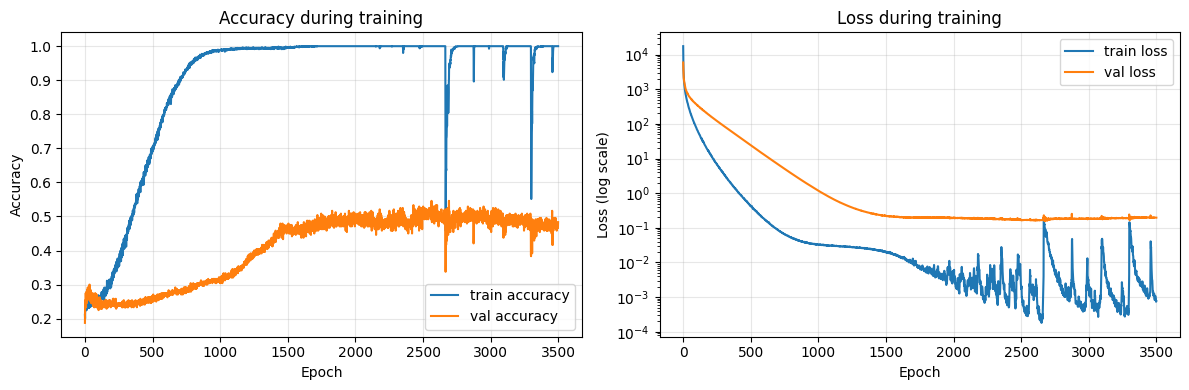

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['accuracy'], label='train accuracy')
ax1.plot(history.history['val_accuracy'], label='val accuracy')
ax1.set_title('Accuracy during training')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
# ax1.set_xscale('log')  # Optional: standard grokking paper view
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='train loss')
ax2.plot(history.history['val_loss'], label='val loss')
ax2.set_title('Loss during training')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (log scale)')
ax2.set_yscale('log')
# ax2.set_xscale('log')  # Optional: standard grokking paper view
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# epochs = np.arange(1, len(train_acc) + 1)

# axes[0].plot(epochs, train_acc, label='train accuracy', color='tab:blue')
# axes[0].plot(epochs, val_acc, label='val accuracy', color='tab:orange')
# axes[0].set_title('Accuracy during training')
# axes[0].set_xlabel('Epoch')
# axes[0].set_ylabel('Accuracy')
# axes[0].legend()
# axes[0].grid(alpha=0.3)

# loss = history.history['loss']
# val_loss = history.history['val_loss']
# axes[1].plot(epochs, loss, label='train loss', color='tab:blue')
# axes[1].plot(epochs, val_loss, label='val loss', color='tab:orange')
# axes[1].set_title('Loss during training')
# axes[1].set_xlabel('Epoch')
# axes[1].set_ylabel('Loss')
# axes[1].legend()
# axes[1].grid(alpha=0.3)

# plt.tight_layout()
# plt.show()
